In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# load clean data
df = pd.read_csv("Downloads/henderson_clean_final_data.csv", index_col="datetime", parse_dates=True)
df.head()

,NO2,PM10,RH,Temp,WS
datetime,,,,,
2006-01-01 00:00:00,1.50,18.4,80.3,19.0,1.3
2006-01-01 01:00:00,0.76,32.6,81.1,19.0,3.1
2006-01-01 02:00:00,0.46,18.6,80.4,20.0,2.7
2006-01-01 03:00:00,0.42,15.1,79.4,20.0,1.6
2006-01-01 04:00:00,0.40,15.6,80.4,20.0,1.4


          PM10   NO2
datetime            
2006      0.99  0.99
2007      0.99  0.99
2008      0.99  0.99
2009      1.00  1.00
2010      1.00  1.00
2011      1.00  0.99
2012      1.00  0.99
2013      1.00  0.99
2014      0.99  0.99
2015      0.93  0.93
2016      0.99  0.99
2017      0.98  0.58
2018      0.88  0.13
2019      0.99  0.98
2020      1.00  1.00
2021      0.99  1.00
2022      0.81  0.82
2023      1.00  0.99


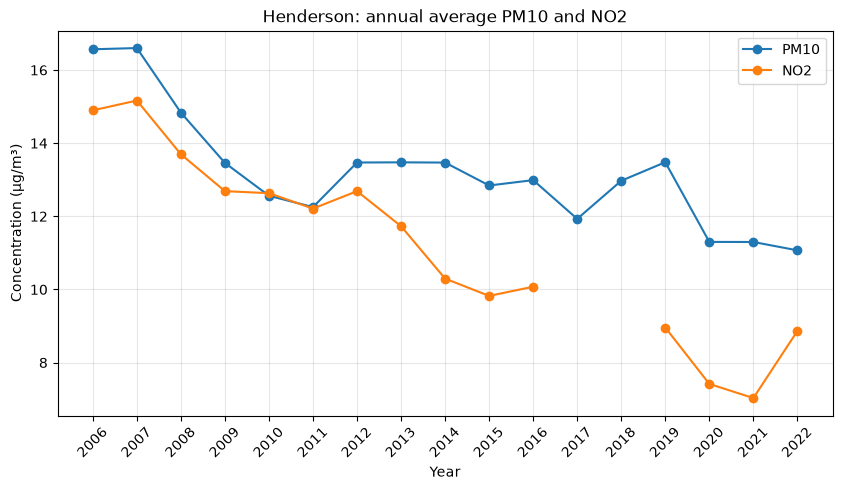

In [9]:
# yearly average and % of hours with data
yearly_mean = df[["PM10", "NO2"]].groupby(df.index.year).mean()
coverage = df[["PM10", "NO2"]].notna().groupby(df.index.year).mean()

# hide years with less than 75% data
yearly_mean = yearly_mean.where(coverage >= 0.75)
# 2023 only has Jan-Feb, so drop it
yearly_mean = yearly_mean.loc[:2022]

print(coverage.round(2))
yearly_mean.round(1)

# plot the trend
yearly_mean.plot(marker="o", figsize=(10, 5))
plt.title("Henderson: annual average PM10 and NO2")
plt.xlabel("Year")
plt.ylabel("Concentration (µg/m³)")
plt.grid(alpha=0.3)
plt.xticks(yearly_mean.index, rotation=45)
plt.show()

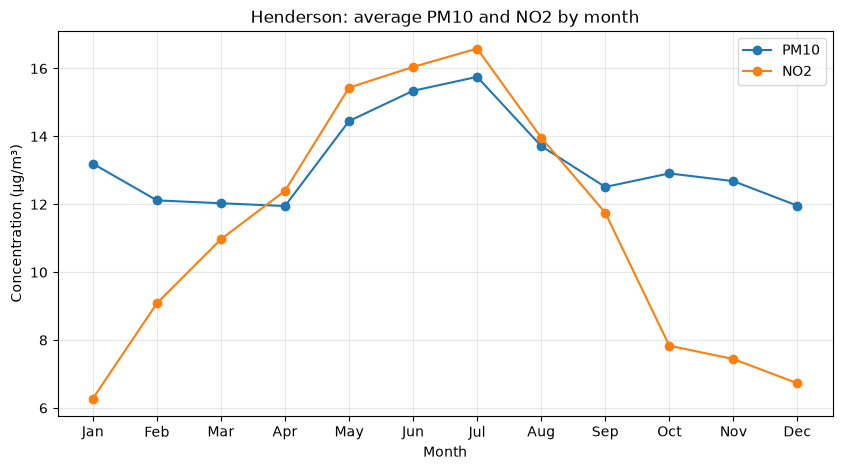

In [11]:
# average for each month across all years
monthly = df[["PM10", "NO2"]].groupby(df.index.month).mean()

# plot
monthly.plot(marker="o", figsize=(10, 5))
plt.title("Henderson: average PM10 and NO2 by month")
plt.xlabel("Month")
plt.ylabel("Concentration (µg/m³)")
plt.xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.grid(alpha=0.3)
plt.show()

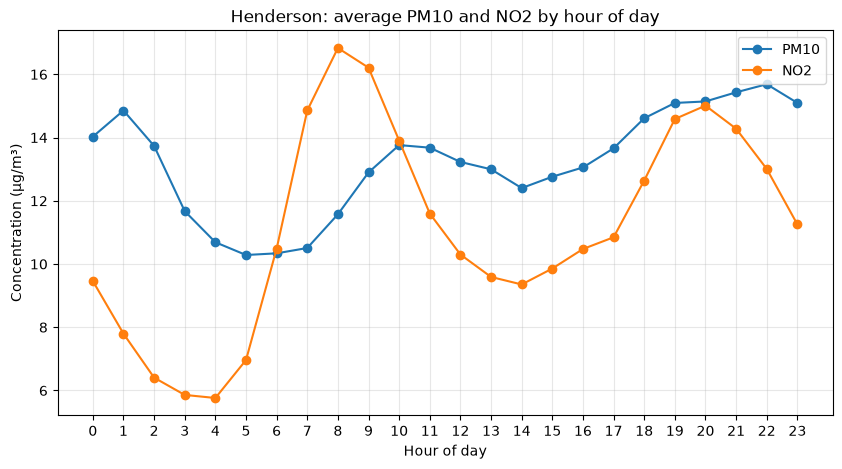

In [13]:
# average for each hour of the day across all years
hourly = df[["PM10", "NO2"]].groupby(df.index.hour).mean()

# plot
hourly.plot(marker="o", figsize=(10, 5))
plt.title("Henderson: average PM10 and NO2 by hour of day")
plt.xlabel("Hour of day")
plt.ylabel("Concentration (µg/m³)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.show()

        PM10   NO2
Season            
Summer  12.4   7.3
Autumn  12.8  13.0
Winter  14.9  15.6
Spring  12.7   9.0


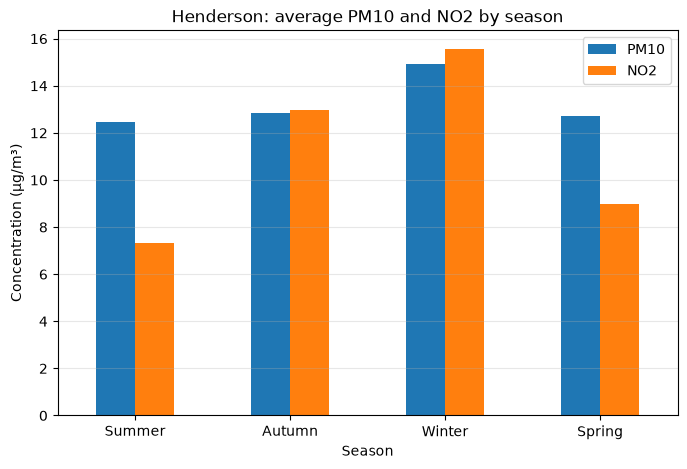

In [27]:
# map each month to an NZ season
season_map = {12: "Summer", 1: "Summer", 2: "Summer",
              3: "Autumn", 4: "Autumn", 5: "Autumn",
              6: "Winter", 7: "Winter", 8: "Winter",
              9: "Spring", 10: "Spring", 11: "Spring"}
df["Season"] = df.index.month.map(season_map)

# average per season, in calendar order
order = ["Summer", "Autumn", "Winter", "Spring"]
by_season = df.groupby("Season")[["PM10", "NO2"]].mean().loc[order]
print(by_season.round(1))

# bar chart
by_season.plot(kind="bar", figsize=(8, 5), rot=0)
plt.title("Henderson: average PM10 and NO2 by season")
plt.xlabel("Season")
plt.ylabel("Concentration (µg/m³)")
plt.grid(axis="y", alpha=0.3)
plt.show()

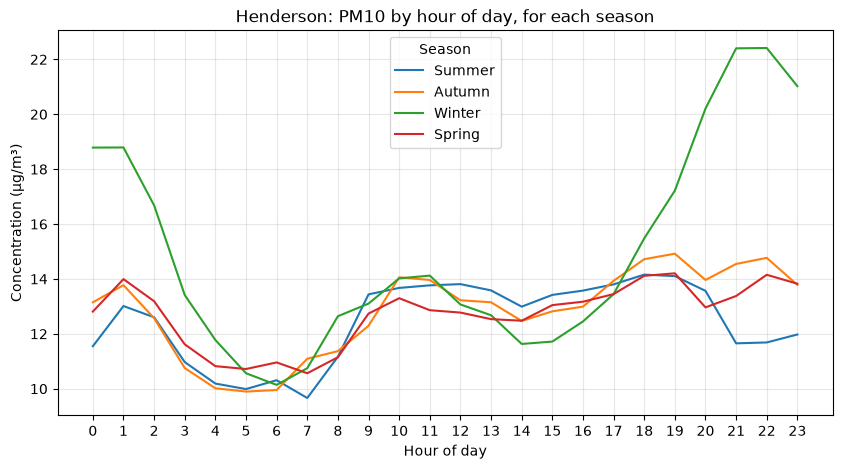

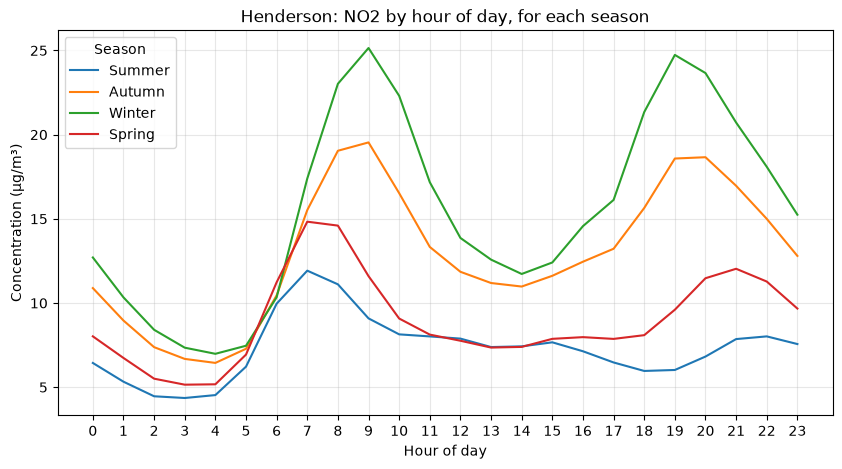

In [31]:
# daily pattern for each season
for col in ["PM10", "NO2"]:
    season_hour = df.groupby(["Season", df.index.hour])[col].mean().unstack(0)[order]
    season_hour.plot(figsize=(10, 5))
    plt.title(f"Henderson: {col} by hour of day, for each season")
    plt.xlabel("Hour of day")
    plt.ylabel("Concentration (µg/m³)")
    plt.xticks(range(0, 24))
    plt.grid(alpha=0.3)
    plt.show()

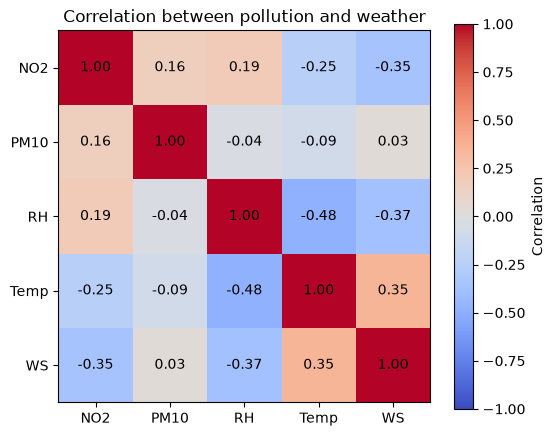

In [21]:
# correlation between all variables (-1 to 1)
corr = df.corr()
corr.round(2)


# heatmap of the correlations
plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr)), corr.columns)
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Correlation between pollution and weather")
plt.show()

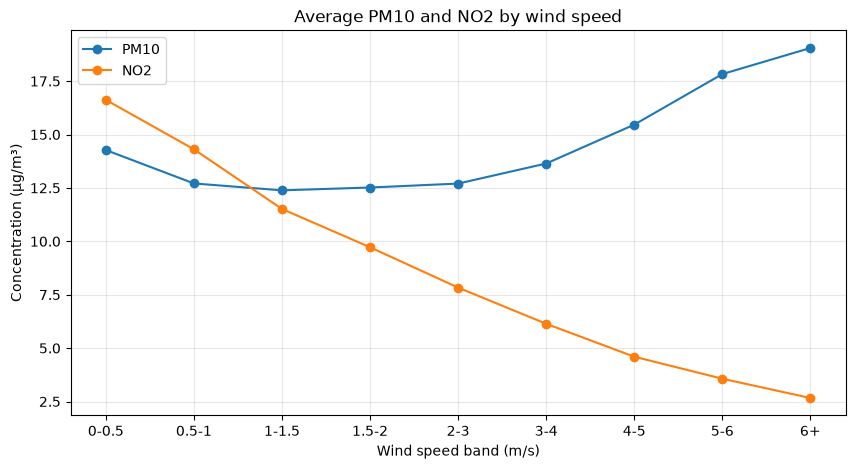

In [25]:
# group wind speed into bands
bins = [0, 0.5, 1, 1.5, 2, 3, 4, 5, 6, 11]
df["WS_band"] = pd.cut(df["WS"], bins=bins, include_lowest=True)

# average pollution in each band
by_wind = df.groupby("WS_band", observed=True)[["PM10", "NO2"]].mean()

# plot
by_wind.plot(marker="o", figsize=(10, 5))
plt.title("Average PM10 and NO2 by wind speed")
plt.xlabel("Wind speed band (m/s)")
plt.ylabel("Concentration (µg/m³)")
plt.grid(alpha=0.3)
plt.xticks(range(len(by_wind)), ["0-0.5", "0.5-1", "1-1.5", "1.5-2", "2-3", "3-4", "4-5", "5-6", "6+"])
plt.show()


# remove the helper column
df = df.drop(columns="WS_band")

                                            feature engineering

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Downloads/henderson_clean_final_data.csv", index_col="datetime", parse_dates=True)
df.head()

,NO2,PM10,RH,Temp,WS
datetime,,,,,
2006-01-01 00:00:00,1.50,18.4,80.3,19.0,1.3
2006-01-01 01:00:00,0.76,32.6,81.1,19.0,3.1
2006-01-01 02:00:00,0.46,18.6,80.4,20.0,2.7
2006-01-01 03:00:00,0.42,15.1,79.4,20.0,1.6
2006-01-01 04:00:00,0.40,15.6,80.4,20.0,1.4


In [38]:
def make_features(df, target):
    X = pd.DataFrame(index=df.index)

    # time features
    X["hour"] = df.index.hour
    X["month"] = df.index.month
    X["dayofweek"] = df.index.dayofweek
    X["is_weekend"] = (X["dayofweek"] >= 5).astype(int)

    # current weather
    for col in ["Temp", "RH", "WS"]:
        X[col] = df[col]

    # past pollution values (lag0 = now, lag1 = 1 hour ago, lag24 = same time yesterday)
    for lag in [0, 1, 2, 3, 24]:
        X[f"{target}_lag{lag}"] = df[target].shift(lag)

    # recent averages
    X[f"{target}_roll3"] = df[target].rolling(3).mean()
    X[f"{target}_roll24"] = df[target].rolling(24).mean()

    # target = value next hour
    y = df[target].shift(-1).rename("target")

    # drop rows with any missing value
    return pd.concat([X, y], axis=1).dropna()

In [40]:
# build data for each pollutant and split by time
data = {}
for t in ["PM10", "NO2"]:
    d = make_features(df, t)
    data[t] = {"train": d.loc[:"2018"], "test": d.loc["2019"]}
    print(t, "train:", len(data[t]["train"]), "test:", len(data[t]["test"]))

PM10 train: 106718 test: 8671
NO2 train: 98746 test: 8461


In [42]:
%pip install xgboost lightgbm

Note: you may need to restart the kernel to use updated packages.


In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# score one set of predictions
def evaluate(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

results = []

# naive baseline: next hour = this hour
for t in ["PM10", "NO2"]:
    test = data[t]["test"]
    score = evaluate(test["target"], test[f"{t}_lag0"])
    results.append({"Target": t, "Model": "Naive baseline", **score})

pd.DataFrame(results).round(3)

,Target,Model,MAE,RMSE,R2
0,PM10,Naive baseline,5.265,6.949,0.155
1,NO2,Naive baseline,3.292,5.531,0.654


In [46]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

In [82]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# score predictions
def evaluate(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

# actual vs predicted graph
def plot_model(t, name, start="2019-07-01", end="2019-07-14"):
    test = data[t]["test"]
    actual = test["target"]
    pred = pd.Series(predictions[(t, name)], index=test.index)
    m = evaluate(actual, pred)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2.5, 1]})

    axes[0].plot(actual.loc[start:end], label="Actual", color="blue", linewidth=1.5)
    axes[0].plot(pred.loc[start:end], label="Predicted", color="red", linewidth=1.2)
    axes[0].set_title(f"{start} to {end}")
    axes[0].set_xlabel("Date")
    axes[0].set_ylabel(f"{t} (µg/m³)")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].scatter(actual, pred, s=4, alpha=0.3)
    lim = [0, max(actual.max(), pred.max())]
    axes[1].plot(lim, lim, color="red", linestyle="--", label="Perfect prediction")
    axes[1].set_title("All of 2019")
    axes[1].set_xlabel("Actual")
    axes[1].set_ylabel("Predicted")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.suptitle(f"{t} — {name}   |   MAE = {m['MAE']:.2f}   RMSE = {m['RMSE']:.2f}   R² = {m['R2']:.3f}",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

results = []
predictions = {}

# train, test, print metrics, plot
def run_model(name, model):
    for t in ["PM10", "NO2"]:
        X_train = data[t]["train"].drop(columns="target")
        y_train = data[t]["train"]["target"]
        X_test = data[t]["test"].drop(columns="target")
        y_test = data[t]["test"]["target"]

        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        predictions[(t, name)] = pred

        m = evaluate(y_test, pred)
        results.append({"Target": t, "Model": name, **m})
        print(f"{name} — {t}:  MAE = {m['MAE']:.3f}   RMSE = {m['RMSE']:.3f}   R² = {m['R2']:.3f}")

        plot_model(t, name)

Linear Regression — PM10:  MAE = 4.451   RMSE = 5.869   R² = 0.397


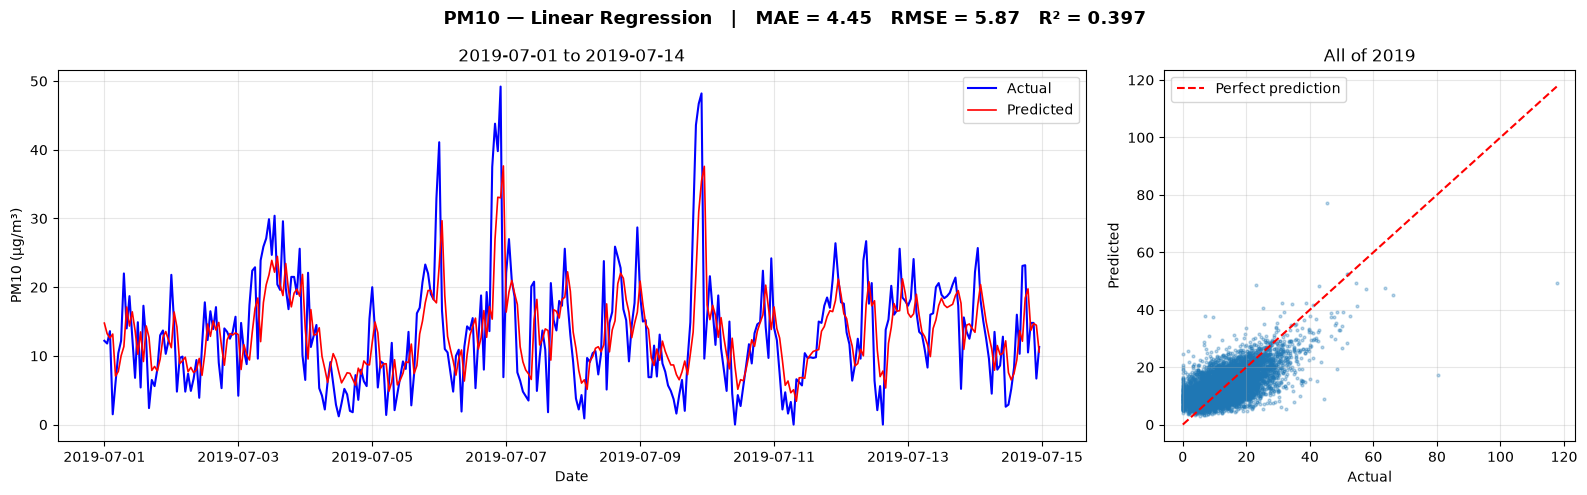

Linear Regression — NO2:  MAE = 3.299   RMSE = 5.075   R² = 0.709


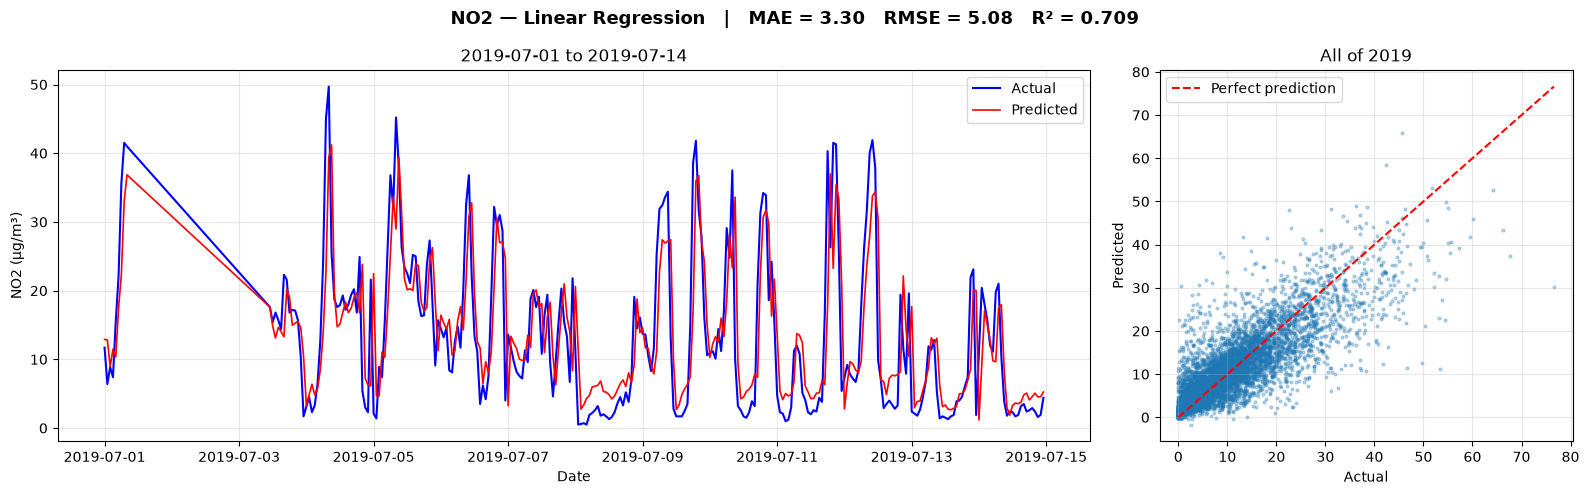

In [108]:
# Model 1: Linear Regression
from sklearn.linear_model import LinearRegression
run_model("Linear Regression", LinearRegression())

Decision Tree — PM10:  MAE = 4.435   RMSE = 5.984   R² = 0.374


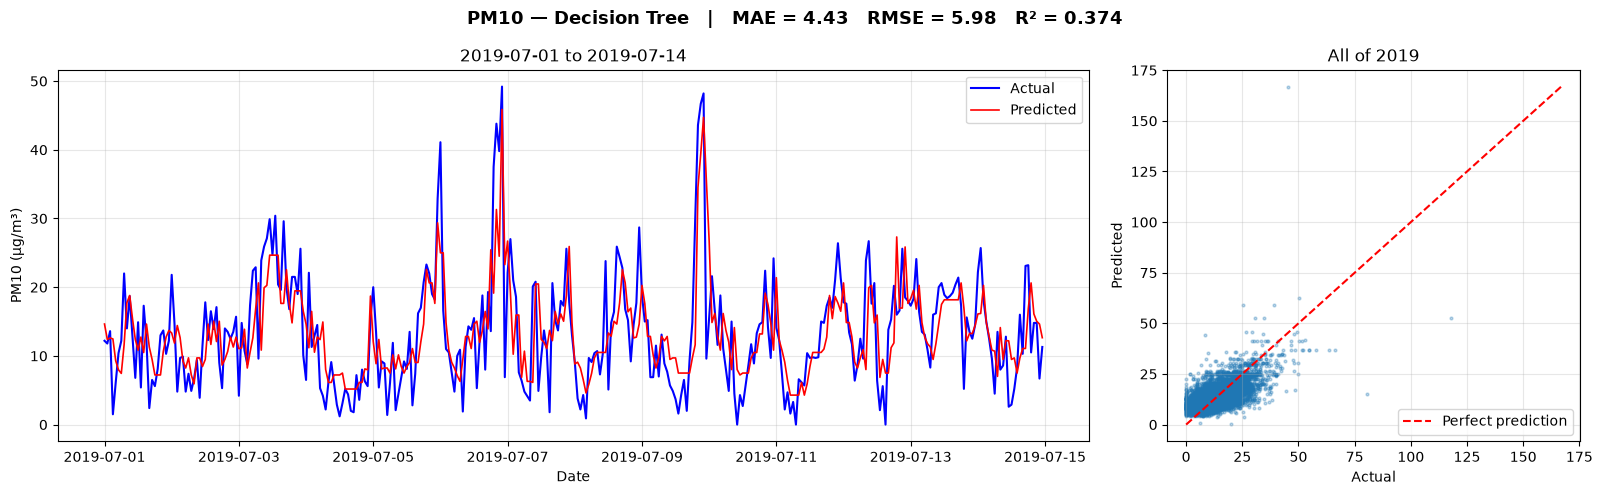

Decision Tree — NO2:  MAE = 3.036   RMSE = 4.889   R² = 0.730


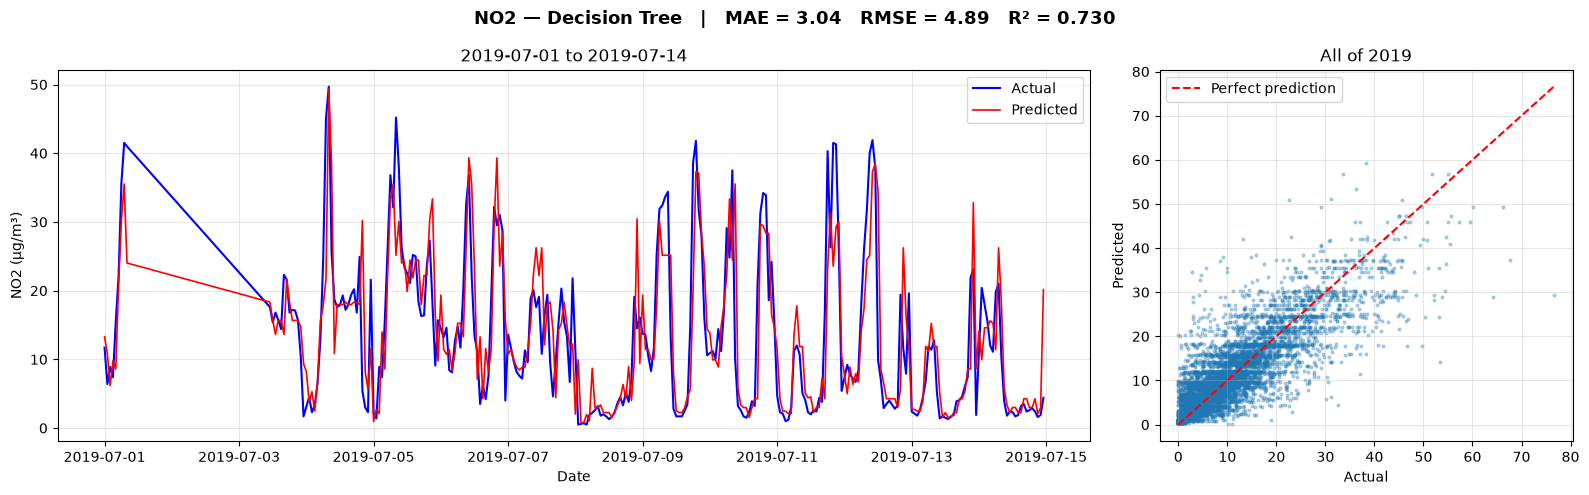

In [110]:
# Model 2: Decision Tree
from sklearn.tree import DecisionTreeRegressor
run_model("Decision Tree", DecisionTreeRegressor(max_depth=10, random_state=42))

Random Forest — PM10:  MAE = 4.273   RMSE = 5.631   R² = 0.445


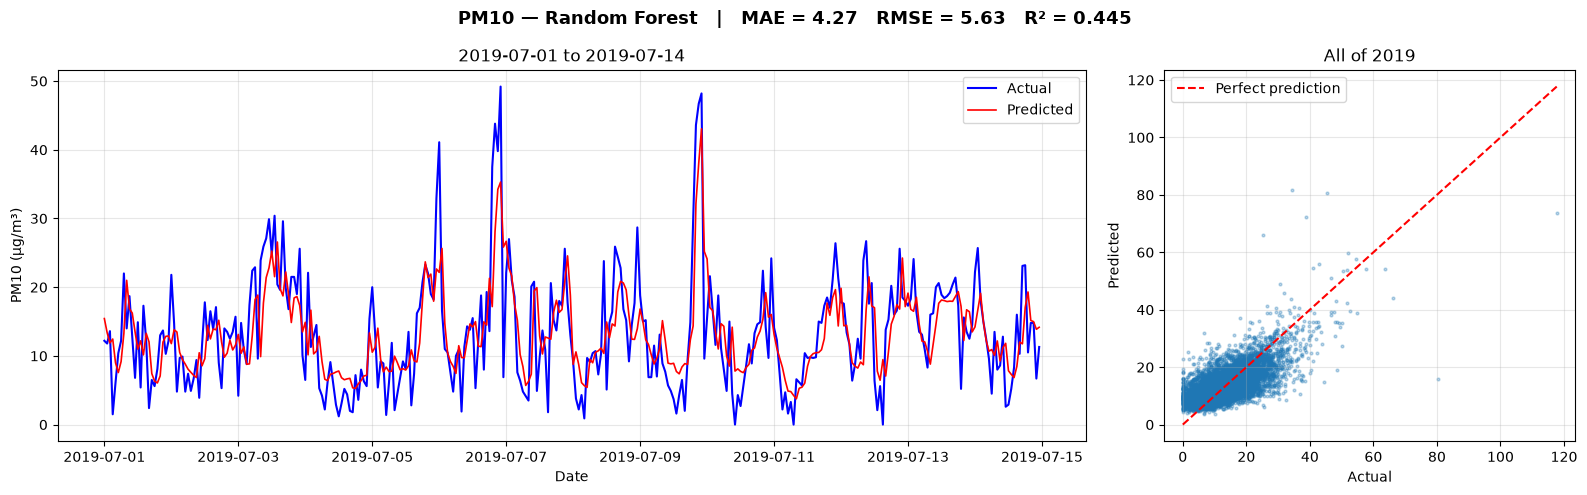

Random Forest — NO2:  MAE = 2.837   RMSE = 4.516   R² = 0.769


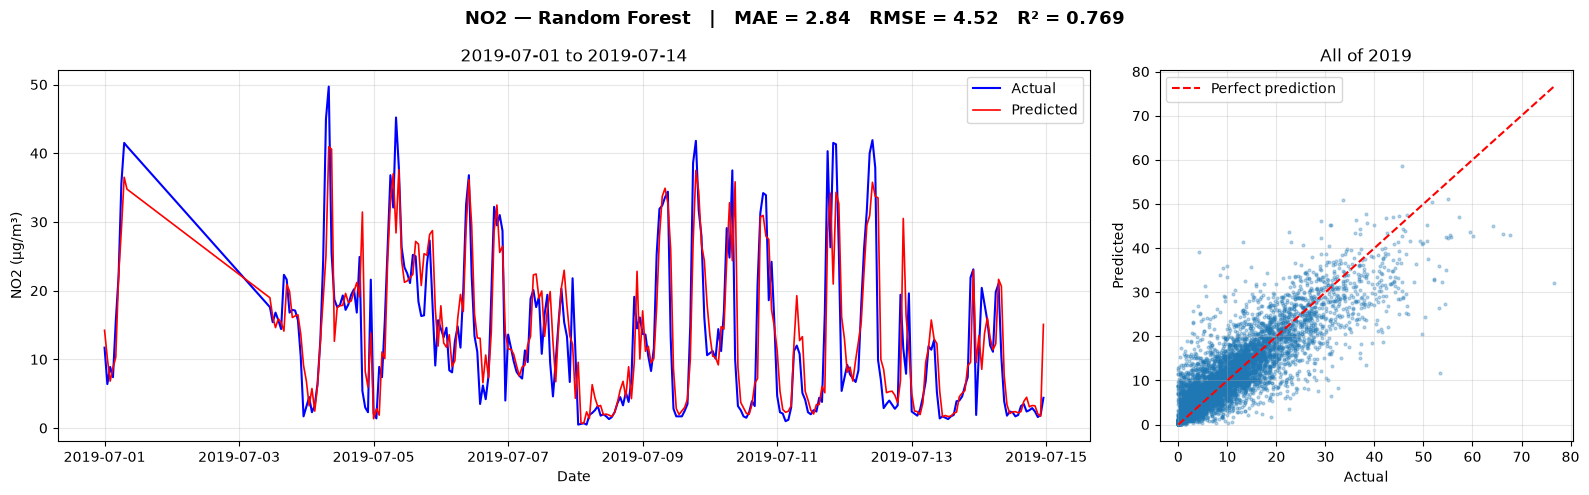

In [112]:
# Model 3: Random Forest
from sklearn.ensemble import RandomForestRegressor
run_model("Random Forest", RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42))

XGBoost (tuned) — PM10:  MAE = 4.261   RMSE = 5.779   R² = 0.416


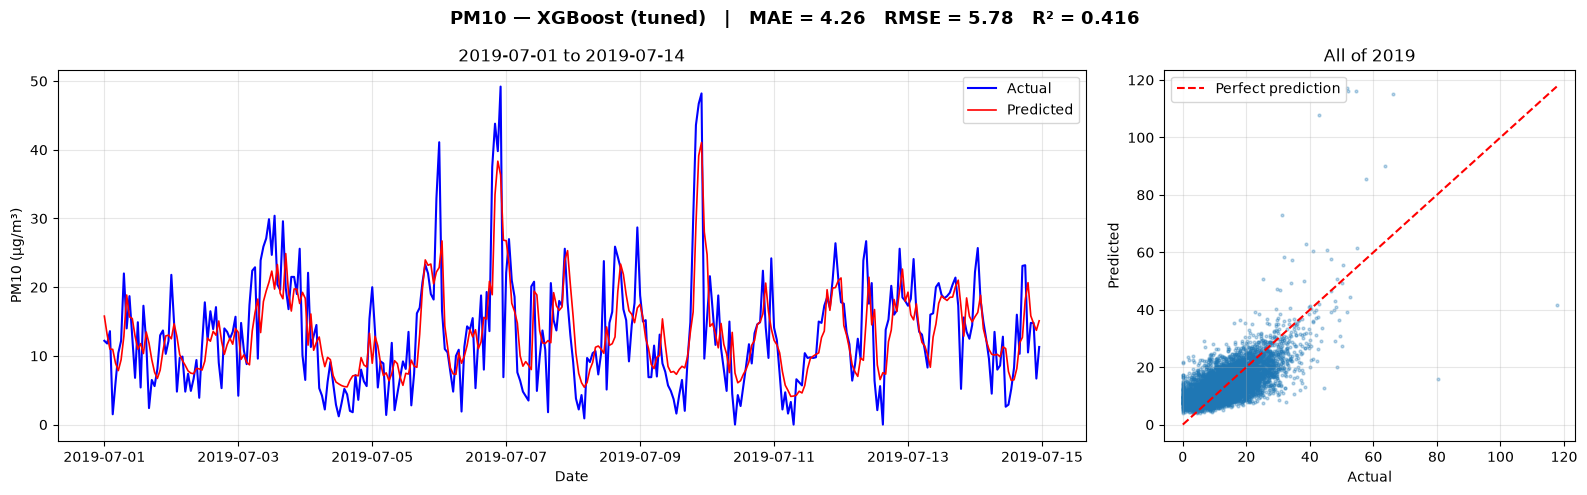

XGBoost (tuned) — NO2:  MAE = 2.827   RMSE = 4.437   R² = 0.777


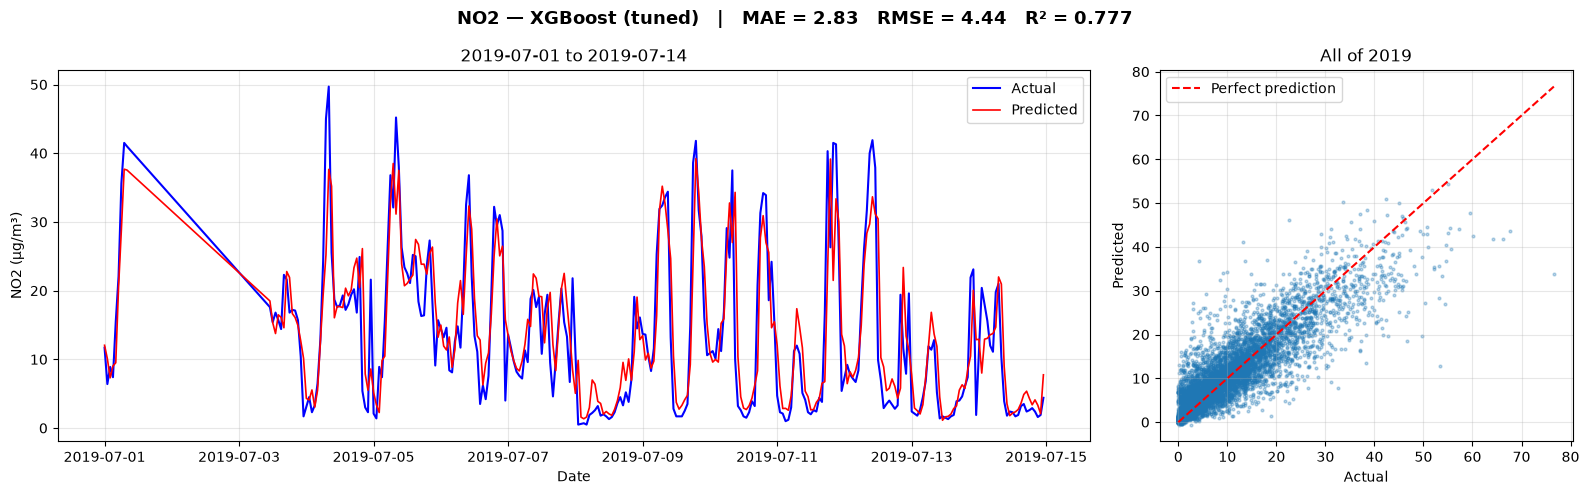

In [114]:
# Model 4b: XGBoost with stricter settings
run_model("XGBoost (tuned)", XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
                                          min_child_weight=20, random_state=42))

In [102]:
# did the tuned model fix 6 December?
check = pd.DataFrame({"actual": test["target"],
                      "original": predictions[("PM10", "XGBoost")],
                      "tuned": predictions[("PM10", "XGBoost (tuned)")]}, index=test.index)
check.loc["2019-12-06 08:00":"2019-12-06 16:00"].round(1)

,actual,original,tuned
datetime,,,
2019-12-06 08:00:00,48.5,44.500000,50.799999
2019-12-06 09:00:00,54.9,51.200001,61.400002
2019-12-06 10:00:00,66.1,254.100006,115.099998
2019-12-06 11:00:00,51.6,266.299988,117.400002
2019-12-06 12:00:00,63.7,141.100006,90.000000
2019-12-06 13:00:00,52.1,183.199997,116.199997
2019-12-06 14:00:00,57.6,149.100006,85.599998
2019-12-06 15:00:00,54.5,141.899994,116.000000
2019-12-06 16:00:00,43.0,91.300003,107.900002


LightGBM — PM10:  MAE = 4.243   RMSE = 5.772   R² = 0.417


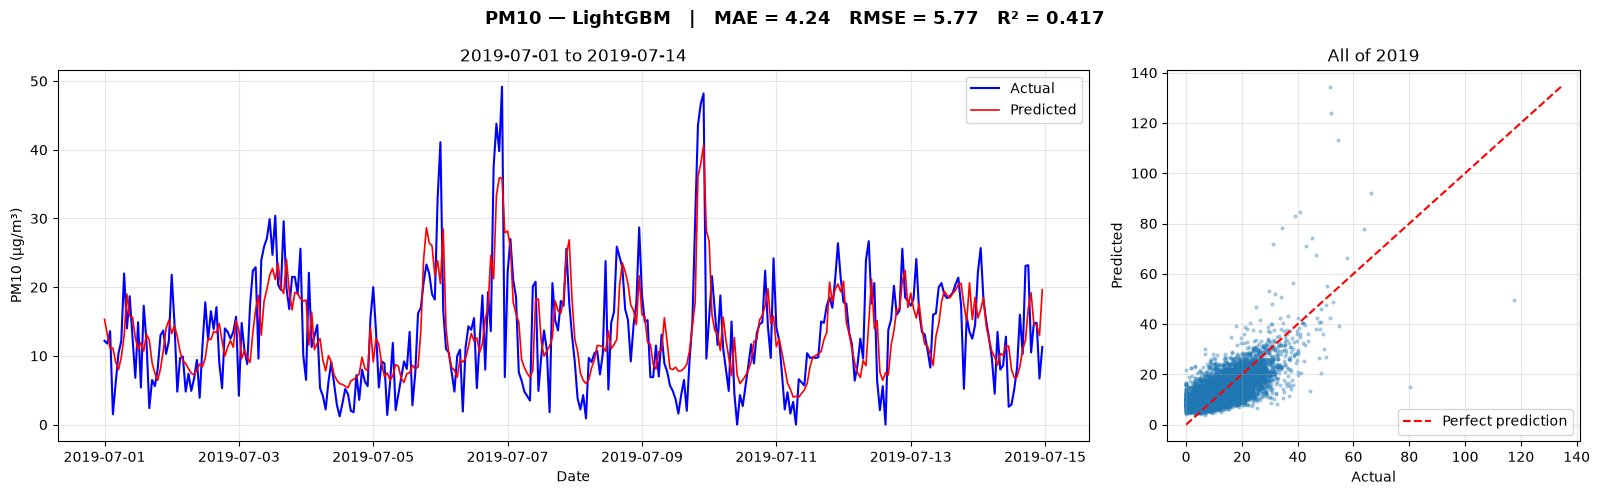

LightGBM — NO2:  MAE = 2.735   RMSE = 4.320   R² = 0.789


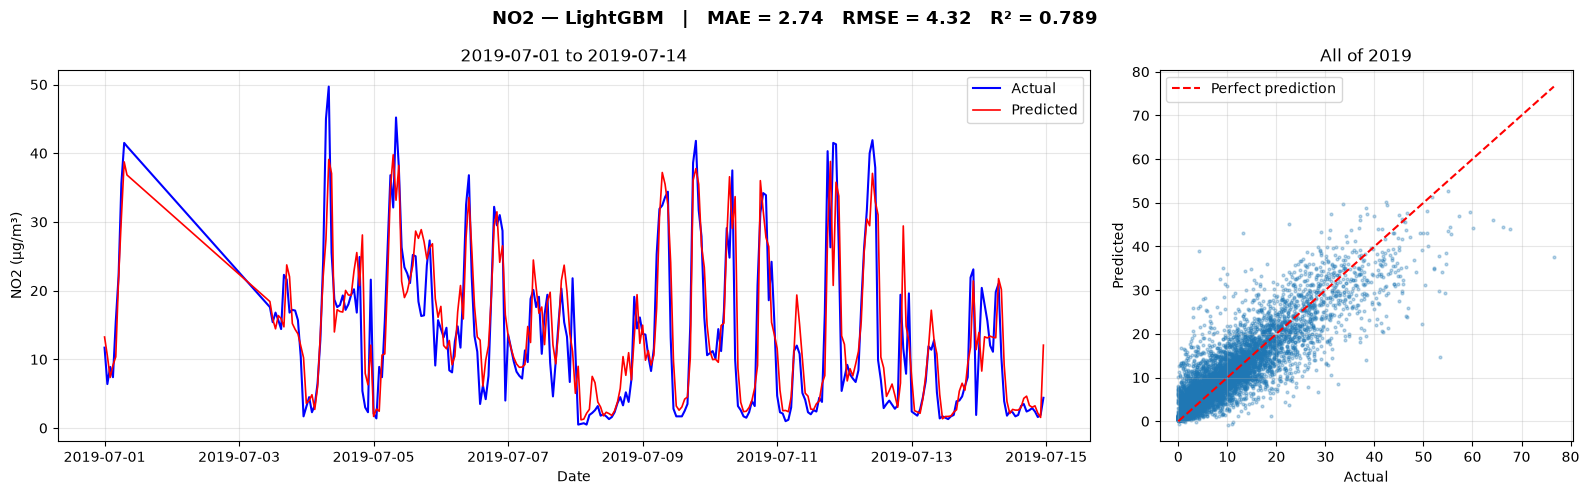

In [116]:
# Model 5: LightGBM
from lightgbm import LGBMRegressor
run_model("LightGBM", LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1))

In [122]:
# final comparison: drop the original XGBoost, keep the tuned one
res = pd.DataFrame(results).drop_duplicates(subset=["Target", "Model"], keep="last")
res = res[res["Model"] != "XGBoost"].round(3)
res.sort_values(["Target", "R2"], ascending=[True, False])

,Target,Model,MAE,RMSE,R2
21,NO2,LightGBM,2.735,4.320,0.789
19,NO2,XGBoost (tuned),2.827,4.437,0.777
17,NO2,Random Forest,2.837,4.516,0.769
15,NO2,Decision Tree,3.036,4.889,0.730
13,NO2,Linear Regression,3.299,5.075,0.709
16,PM10,Random Forest,4.273,5.631,0.445
20,PM10,LightGBM,4.243,5.772,0.417
18,PM10,XGBoost (tuned),4.261,5.779,0.416
12,PM10,Linear Regression,4.451,5.869,0.397
14,PM10,Decision Tree,4.435,5.984,0.374


In [124]:
# naive baseline: next hour = this hour
for t in ["PM10", "NO2"]:
    test = data[t]["test"]
    results.append({"Target": t, "Model": "Naive baseline",
                    **evaluate(test["target"], test[f"{t}_lag0"])})

In [128]:
%pip install prophet

   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
    --------------------------------------- 0.3/12.1 MB ? eta -:--:--
   -- ------------------------------------- 0.8/12.1 MB 2.0 MB/s eta 0:00:06
   --- ------------------------------------ 1.0/12.1 MB 2.2 MB/s eta 0:00:06
   ----- ---------------------------------- 1.6/12.1 MB 2.0 MB/s eta 0:00:06
   ------ --------------------------------- 2.1/12.1 MB 2.1 MB/s eta 0:00:05
   -------- ------------------------------- 2.6/12.1 MB 2.2 MB/s eta 0:00:05
   ----------- ---------------------------- 3.4/12.1 MB 2.3 MB/s eta 0:00:04
   ------------ --------------------------- 3.9/12.1 MB 2.4 MB/s eta 0:00:04
   --------------- ------------------------ 4.7/12.1 MB 2.4 MB/s eta 0:00:04
   ----------------- ---------------------- 5.2/12.1 MB 2.5 MB/s eta 0:00:03
   ------------------- -------------------- 5.8/12.1 MB 2.5 MB/s eta 0:00:03
   -------------------- ------------------- 6.3/12.1 MB 2.5 MB/s eta 0:00:03
   ----------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


17:12:37 - cmdstanpy - INFO - Chain [1] start processing
17:13:45 - cmdstanpy - INFO - Chain [1] done processing


Prophet — PM10:  MAE = 5.620   RMSE = 7.523   R² = 0.010


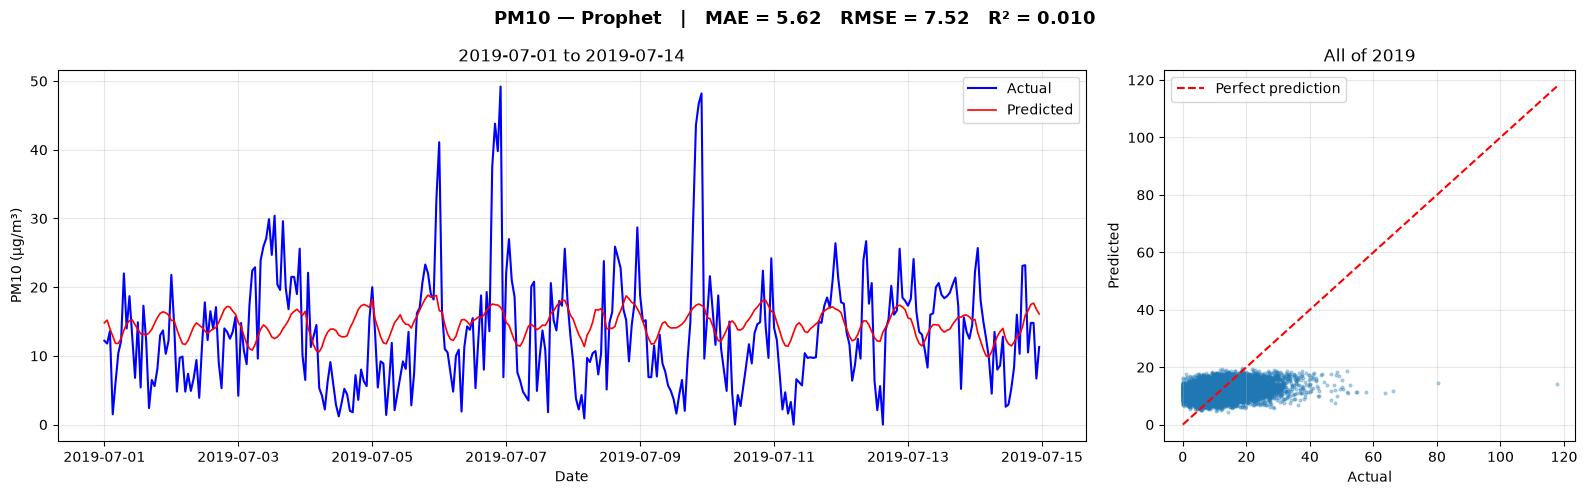

17:14:12 - cmdstanpy - INFO - Chain [1] start processing
17:15:18 - cmdstanpy - INFO - Chain [1] done processing


Prophet — NO2:  MAE = 5.710   RMSE = 7.466   R² = 0.370


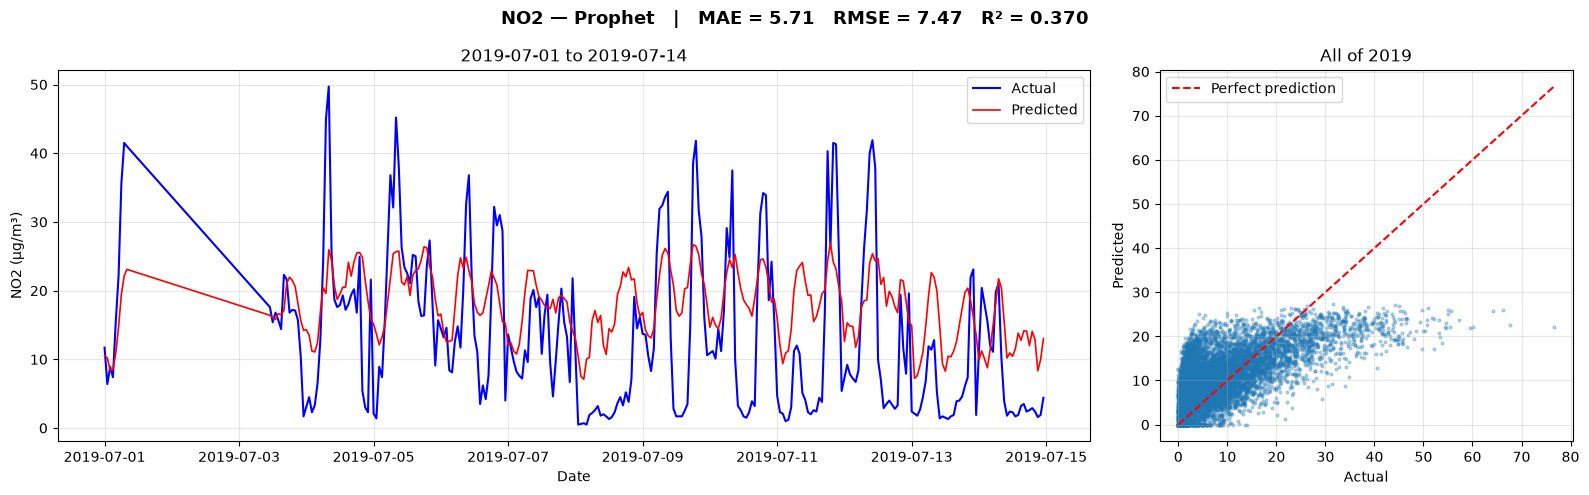

In [130]:
# Model 6: Prophet
from prophet import Prophet

for t in ["PM10", "NO2"]:
    train, test = data[t]["train"], data[t]["test"]

    # Prophet needs columns: ds (time), y (value) + weather regressors
    # target is next hour, so ds = this hour + 1
    def to_prophet(d):
        return pd.DataFrame({"ds": d.index + pd.Timedelta(hours=1),
                             "y": d["target"].values,
                             "Temp": d["Temp"].values,
                             "RH": d["RH"].values,
                             "WS": d["WS"].values})

    p_train, p_test = to_prophet(train), to_prophet(test)

    # build model with daily, weekly, yearly patterns + weather
    m = Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=True)
    for reg in ["Temp", "RH", "WS"]:
        m.add_regressor(reg)
    m.fit(p_train)

    # predict 2019
    pred = m.predict(p_test.drop(columns="y"))["yhat"].clip(lower=0).values
    predictions[(t, "Prophet")] = pred

    # metrics + graph
    score = evaluate(test["target"], pred)
    results.append({"Target": t, "Model": "Prophet", **score})
    print(f"Prophet — {t}:  MAE = {score['MAE']:.3f}   RMSE = {score['RMSE']:.3f}   R² = {score['R2']:.3f}")
    plot_model(t, "Prophet")

In [136]:
# compare all models (one row per model)
res = pd.DataFrame(results).drop_duplicates(subset=["Target", "Model"], keep="last").round(3)
res = res[res["Model"] != "XGBoost"].round(3)
res.sort_values(["Target", "R2"], ascending=[True, False])

,Target,Model,MAE,RMSE,R2
21,NO2,LightGBM,2.735,4.320,0.789
19,NO2,XGBoost (tuned),2.827,4.437,0.777
17,NO2,Random Forest,2.837,4.516,0.769
15,NO2,Decision Tree,3.036,4.889,0.730
13,NO2,Linear Regression,3.299,5.075,0.709
23,NO2,Naive baseline,3.292,5.531,0.654
25,NO2,Prophet,5.710,7.466,0.370
16,PM10,Random Forest,4.273,5.631,0.445
20,PM10,LightGBM,4.243,5.772,0.417
18,PM10,XGBoost (tuned),4.261,5.779,0.416


In [146]:
# Keep only the six final models (no baseline, no untuned XGBoost).

comparable_results = (

    res[
        ~res[
            'Model'
        ].isin(
            ['Naive baseline', 'XGBoost']
        )
    ]

    .copy()
)

# Pick the model with the lowest RMSE for each pollutant.

best_models = (

    comparable_results

    .sort_values(
        'RMSE'
    )

    .groupby(
        'Target',
        as_index=False
    )

    .first()
)

print(
    "Best one-hour-ahead model for PM10 and NO2:"
)

display(
    best_models
)

Best one-hour-ahead model for PM10 and NO2:


,Target,Model,MAE,RMSE,R2
0,NO2,LightGBM,2.735,4.320,0.789
1,PM10,Random Forest,4.273,5.631,0.445


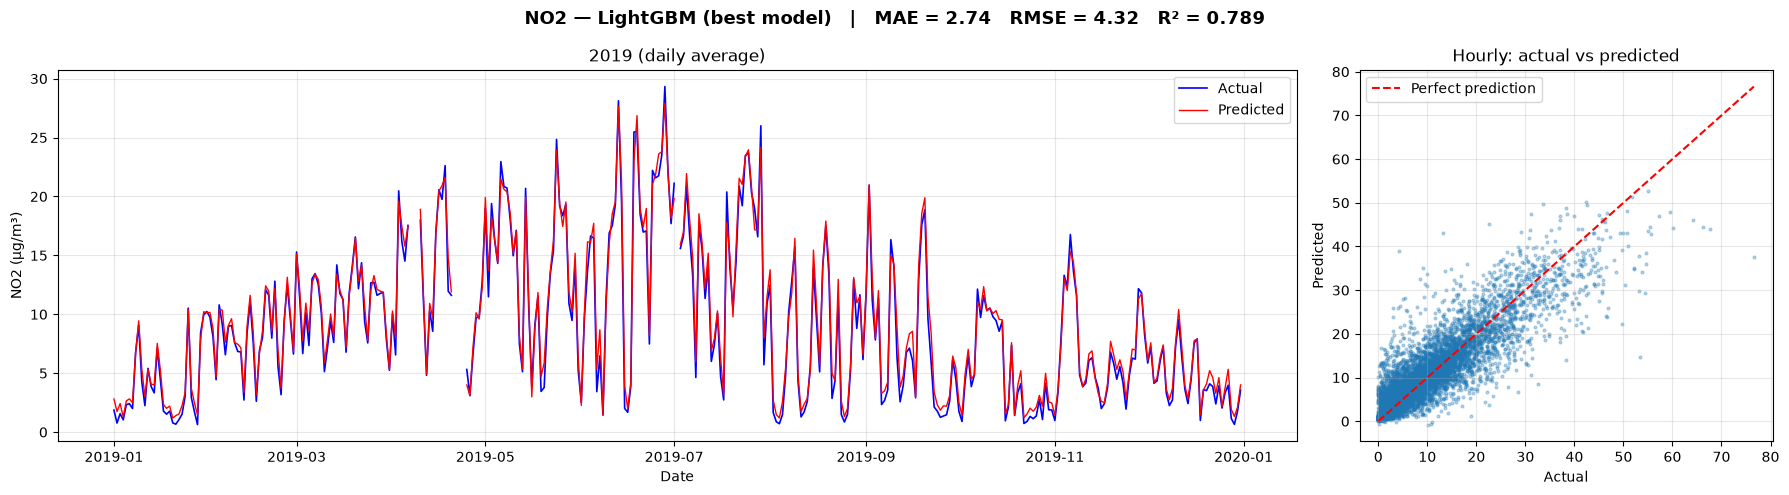

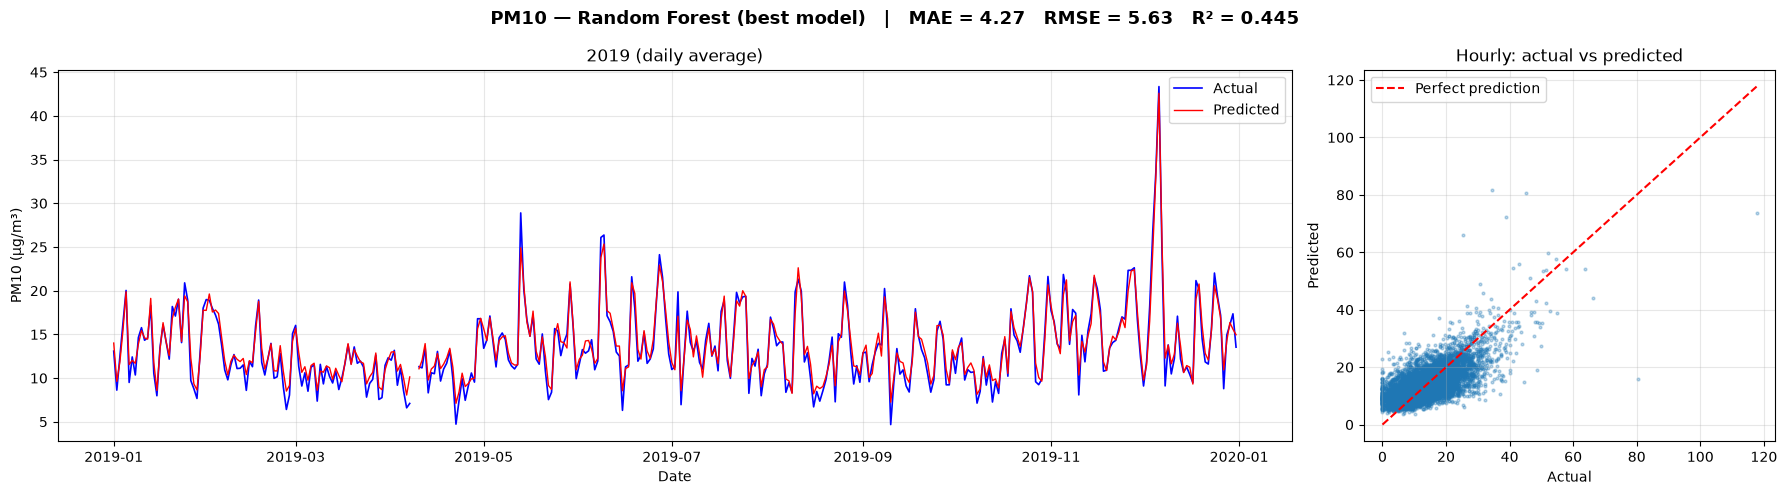

In [152]:
# One figure per best model: full-year actual vs predicted + scatter.

for _, row in best_models.iterrows():

    t, name = row['Target'], row['Model']
    test = data[t]['test']
    actual = test['target']
    pred = pd.Series(predictions[(t, name)], index=test.index)
    m = evaluate(actual, pred)

    fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [3, 1]})

    # full year, daily averages
    axes[0].plot(actual.resample('D').mean(), label='Actual', color='blue', linewidth=1.2)
    axes[0].plot(pred.resample('D').mean(), label='Predicted', color='red', linewidth=1)
    axes[0].set_title('2019 (daily average)')
    axes[0].set_xlabel('Date')
    axes[0].set_ylabel(f"{t} (µg/m³)")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # scatter, hourly
    axes[1].scatter(actual, pred, s=4, alpha=0.3)
    lim = [0, max(actual.max(), pred.max())]
    axes[1].plot(lim, lim, color='red', linestyle='--', label='Perfect prediction')
    axes[1].set_title('Hourly: actual vs predicted')
    axes[1].set_xlabel('Actual')
    axes[1].set_ylabel('Predicted')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.suptitle(f"{t} — {name} (best model)   |   MAE = {m['MAE']:.2f}   RMSE = {m['RMSE']:.2f}   R² = {m['R2']:.3f}",
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [156]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Model settings, so the winner can be rebuilt by name.

model_lookup = {

    'Linear Regression': lambda: LinearRegression(),

    'Decision Tree': lambda: DecisionTreeRegressor(
        max_depth=10, random_state=42
    ),

    'Random Forest': lambda: RandomForestRegressor(
        n_estimators=100, max_depth=15, n_jobs=-1, random_state=42
    ),

    'XGBoost (tuned)': lambda: XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        min_child_weight=20, random_state=42
    ),

    'LightGBM': lambda: LGBMRegressor(
        n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1
    ),
}

NO2 — LightGBM: top 5 features
hour        22.0
NO2_lag0    13.3
WS           8.1
RH           7.9
NO2_lag1     7.0
dtype: float64 



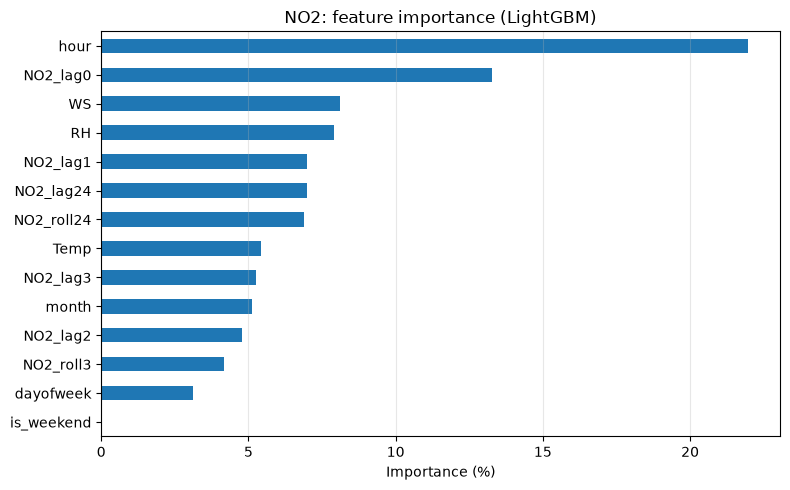

PM10 — Random Forest: top 5 features
PM10_lag0      51.2
PM10_roll3     13.4
PM10_lag24      6.0
hour            5.5
PM10_roll24     5.1
dtype: float64 



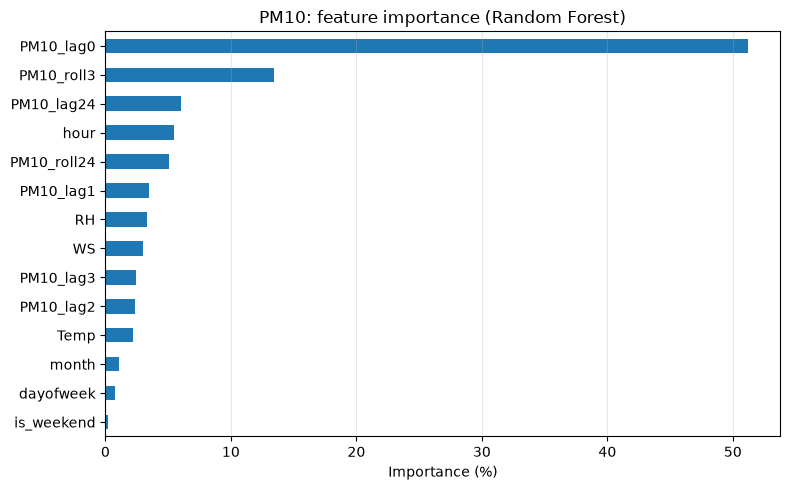

In [158]:
# Feature importance for the best model of each pollutant.

import joblib

trained_best = {}

for _, row in best_models.iterrows():

    t, name = row['Target'], row['Model']

    X_train = data[t]['train'].drop(columns='target')
    y_train = data[t]['train']['target']

    # rebuild and train the winning model
    model = model_lookup[name]()
    model.fit(X_train, y_train)
    trained_best[t] = model

    # importance as % of total
    imp = pd.Series(model.feature_importances_, index=X_train.columns)
    imp = (imp / imp.sum() * 100).sort_values()

    print(f"{t} — {name}: top 5 features")
    print(imp.sort_values(ascending=False).head(5).round(1), "\n")

    # bar chart
    imp.plot(kind='barh', figsize=(8, 5), color='tab:blue')
    plt.title(f"{t}: feature importance ({name})")
    plt.xlabel('Importance (%)')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

    # save the trained model
    joblib.dump(model, f"best_model_{t}.pkl")

In [170]:
import os
import joblib

# save compressed models into a "models" folder for the dashboard
os.makedirs("models", exist_ok=True)
for t, model in trained_best.items():
    joblib.dump(model, f"models/best_model_{t}.pkl", compress=3)
    print(t, round(os.path.getsize(f"models/best_model_{t}.pkl") / 1e6, 1), "MB")

NO2 0.3 MB
PM10 32.3 MB


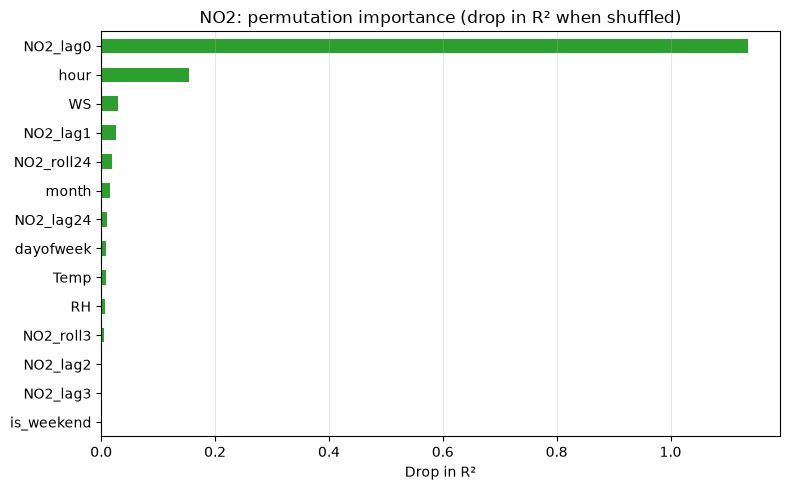

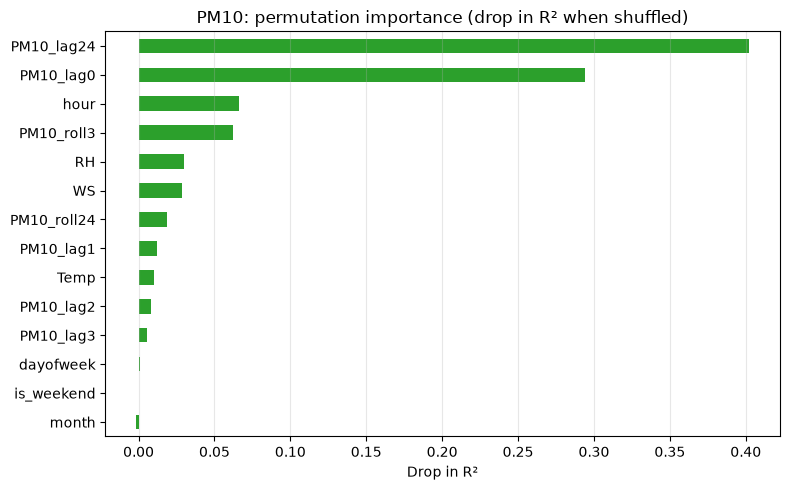

In [160]:
# Permutation importance on the 2019 test data (same method for both models).

from sklearn.inspection import permutation_importance

for t, model in trained_best.items():

    X_test = data[t]['test'].drop(columns='target')
    y_test = data[t]['test']['target']

    perm = permutation_importance(model, X_test, y_test, n_repeats=5,
                                  random_state=42, n_jobs=-1, scoring='r2')

    imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

    imp.plot(kind='barh', figsize=(8, 5), color='tab:green')
    plt.title(f"{t}: permutation importance (drop in R² when shuffled)")
    plt.xlabel('Drop in R²')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

without PM10_lag0: R² = 0.453  (drop -0.008)
without PM10_lag24: R² = 0.447  (drop -0.001)
without hour: R² = 0.422  (drop 0.023)
without RH: R² = 0.434  (drop 0.011)
without WS: R² = 0.434  (drop 0.012)
without Temp: R² = 0.438  (drop 0.007)


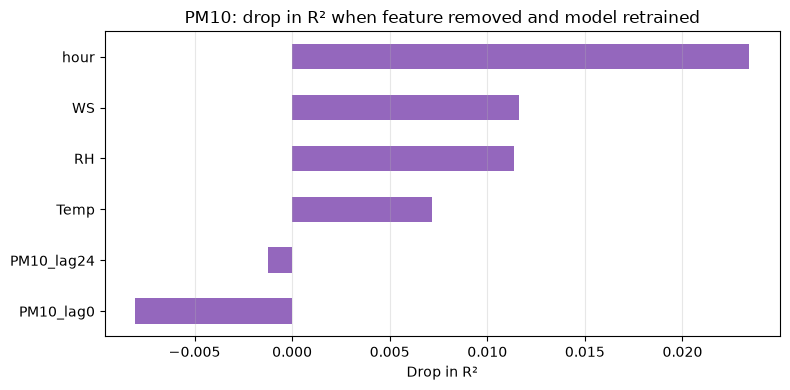

In [162]:
# Drop-column check for PM10: retrain without each key feature.

t = 'PM10'
X_train = data[t]['train'].drop(columns='target')
y_train = data[t]['train']['target']
X_test = data[t]['test'].drop(columns='target')
y_test = data[t]['test']['target']

base_r2 = r2_score(y_test, trained_best[t].predict(X_test))
drops = {}

for feat in ['PM10_lag0', 'PM10_lag24', 'hour', 'RH', 'WS', 'Temp']:
    model = model_lookup['Random Forest']()
    model.fit(X_train.drop(columns=feat), y_train)
    r2 = r2_score(y_test, model.predict(X_test.drop(columns=feat)))
    drops[feat] = base_r2 - r2
    print(f"without {feat}: R² = {r2:.3f}  (drop {base_r2 - r2:.3f})")

pd.Series(drops).sort_values().plot(kind='barh', figsize=(8, 4), color='tab:purple')
plt.title('PM10: drop in R² when feature removed and model retrained')
plt.xlabel('Drop in R²')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [164]:
# Group importance: remove a whole group of features, retrain, compare R².

groups = {
    'Weather': ['Temp', 'RH', 'WS'],
    'Recent pollution': ['lag0', 'lag1', 'lag2', 'lag3', 'lag24', 'roll3', 'roll24'],
    'Time': ['hour', 'month', 'dayofweek', 'is_weekend'],
}

group_results = []

for _, row in best_models.iterrows():

    t, name = row['Target'], row['Model']

    X_train = data[t]['train'].drop(columns='target')
    y_train = data[t]['train']['target']
    X_test = data[t]['test'].drop(columns='target')
    y_test = data[t]['test']['target']

    # R² with all features
    base_r2 = r2_score(y_test, trained_best[t].predict(X_test))

    for group, feats in groups.items():

        # pollution features have the pollutant name in front, e.g. NO2_lag0
        cols = [c for c in X_train.columns if c in feats or c.replace(f"{t}_", "") in feats]

        model = model_lookup[name]()
        model.fit(X_train.drop(columns=cols), y_train)
        r2 = r2_score(y_test, model.predict(X_test.drop(columns=cols)))

        group_results.append({'Target': t, 'Removed': group,
                              'R2 without': round(r2, 3), 'Drop in R2': round(base_r2 - r2, 3)})
        print(f"{t} without {group}: R² = {r2:.3f}  (drop {base_r2 - r2:.3f})")

group_df = pd.DataFrame(group_results)
group_df

NO2 without Weather: R² = 0.782  (drop 0.007)
NO2 without Recent pollution: R² = 0.422  (drop 0.367)
NO2 without Time: R² = 0.737  (drop 0.052)
PM10 without Weather: R² = 0.417  (drop 0.028)
PM10 without Recent pollution: R² = 0.107  (drop 0.338)
PM10 without Time: R² = 0.420  (drop 0.026)


,Target,Removed,R2 without,Drop in R2
0,NO2,Weather,0.782,0.007
1,NO2,Recent pollution,0.422,0.367
2,NO2,Time,0.737,0.052
3,PM10,Weather,0.417,0.028
4,PM10,Recent pollution,0.107,0.338
5,PM10,Time,0.420,0.026


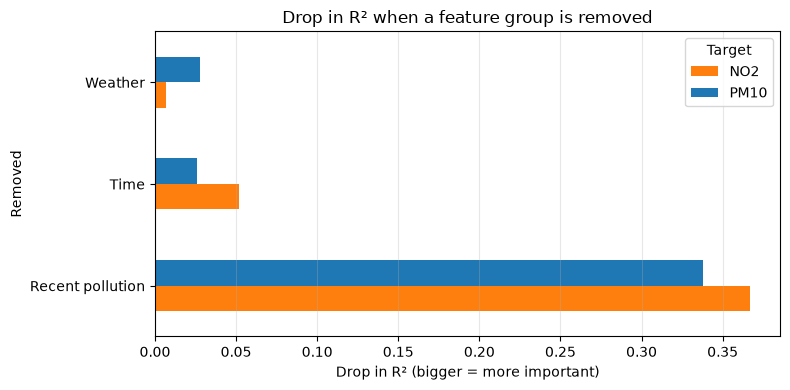

In [166]:
# Chart: drop in R² for each group, both pollutants.

group_df.pivot(index='Removed', columns='Target', values='Drop in R2').plot(
    kind='barh', figsize=(8, 4), color={'NO2': 'tab:orange', 'PM10': 'tab:blue'})
plt.title('Drop in R² when a feature group is removed')
plt.xlabel('Drop in R² (bigger = more important)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [168]:
# save best-model predictions for 2019
rows = []
for _, row in best_models.iterrows():
    t, name = row["Target"], row["Model"]
    test = data[t]["test"]
    rows.append(pd.DataFrame({
        "datetime": test.index + pd.Timedelta(hours=1),   # hour being predicted
        "pollutant": t,
        "model": name,
        "actual": test["target"].values,
        "predicted": predictions[(t, name)],
    }))

pred_df = pd.concat(rows)
pred_df.to_csv("predictions_2019.csv", index=False)
print(pred_df.shape)
pred_df.head()

(17132, 5)


,datetime,pollutant,model,actual,predicted
0,2019-01-01 01:00:00,NO2,LightGBM,0.95,0.027489
1,2019-01-01 02:00:00,NO2,LightGBM,1.70,0.875795
2,2019-01-01 03:00:00,NO2,LightGBM,2.70,2.354271
3,2019-01-01 04:00:00,NO2,LightGBM,2.10,5.781720
4,2019-01-01 05:00:00,NO2,LightGBM,1.00,4.058194
